<a href="https://colab.research.google.com/github/coder-fishing/TrainingAI/blob/main/Phase_3/week10/mini_gpt_end_to_end_vi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini GPT tiếng Việt từ đầu đến cuối

Notebook này làm trọn một dự án nhỏ: nạp truyện tiếng Việt, EDA, tokenizer ký tự, GPT decoder với causal multi-head self-attention, pretraining, đánh giá loss, sinh truyện, lưu checkpoint và instruction fine-tuning.

Mô hình nhỏ để học nguyên lý, không phải chatbot/LLM dùng thực tế. Nên chạy trên Google Colab có GPU. Đọc README trước khi chạy.

## 1. Môi trường và cấu hình

In [ ]:
import os
import random
import re
import statistics
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from datasets import load_dataset

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)

# Bắt đầu nhỏ. Có thể tăng số truyện/số bước khi notebook chạy ổn.
MAX_STORIES = 10000
PRETRAIN_STEPS = 5000
FINETUNE_STEPS = 500
BLOCK_SIZE = 128
BATCH_SIZE = 16
D_MODEL = 64
NUM_HEADS = 4
NUM_LAYERS = 2
DROPOUT = 0.1
EVAL_INTERVAL = 50
LEARNING_RATE = 3e-4
CHECKPOINT_DIR = Path('checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)


PyTorch: 2.11.0+cpu
Device: cpu


## 2. Nạp dataset và xem dữ liệu

In [ ]:
stream = load_dataset(
    'nampdn-ai/tinystories-vietnamese', split='train', streaming=True
)
stories = []
for row in stream.take(MAX_STORIES):
    text = row.get('vi', '')
    if isinstance(text, str) and text.strip():
        stories.append(text)
if not stories:
    raise RuntimeError('Không tải được truyện; kiểm tra Internet và chạy lại cell.')
print('Số truyện đã lấy:', len(stories))
print('Mẫu truyện:\n', stories[0][:800] if stories else 'Không có dữ liệu')


Số truyện đã lấy: 10000
Mẫu truyện:
 Ngày xửa ngày xưa, có một cậu bé tên Tim. Tim thích sưu tầm đồ vật. Một hôm, anh tìm thấy quả bóng to màu đỏ. Nó khiến anh cảm thấy ấm áp và hạnh phúc. Anh muốn cho bạn mình xem, Sue.
Tim đến nhà Sue và nói, "Hãy nhìn quả bóng đỏ của tôi!" Nhưng Sue buồn. Cô ấy nói, "Tôi đã làm mất quả bóng xanh của mình. Bạn có thể giúp tôi tìm nó không?" Tim muốn giúp bạn mình, vì vậy họ đi tìm quả bóng xanh của Sue
Họ tìm khắp công viên, nhưng không thể tìm thấy quả bóng xanh. Sau đó họ nhìn thấy một cái cây lớn với nhiều quả bóng bị mắc kẹt trong đó Tim nói, "Hãy lấy quả bóng màu xanh của bạn từ trên cây!" Họ làm việc cùng nhau và đưa quả bóng màu xanh của Sue xuống. Sue rất vui vẻ và nói, "Cảm ơn Tim!" Bây giờ cả hai đều có những quả bóng và chơi đùa với nhau suốt ngày.


## 3. Làm sạch nhẹ và EDA

Số mẫu: 10000
Mẫu trùng: 0
Độ dài ký tự: min / median / mean / max = 167 731 805.2 4183


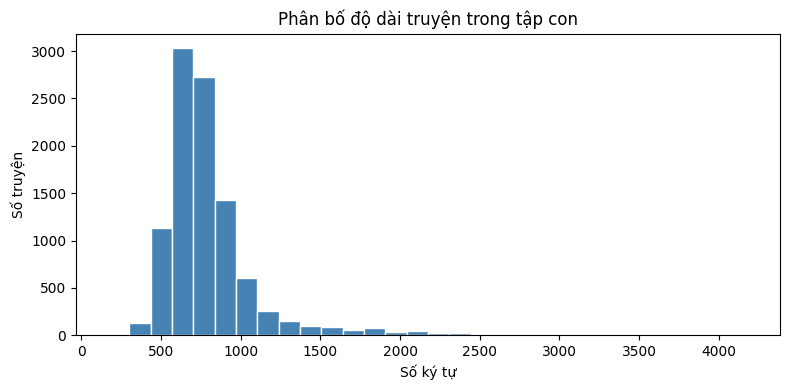

Ký tự phổ biến: [(' ', 1847504), ('n', 665872), ('h', 479601), ('c', 353833), ('t', 343701), ('i', 340275), ('g', 282072), ('m', 225067), ('a', 172344), ('à', 170784), ('u', 154324), ('.', 148852), ('y', 139608), ('v', 139365), ('đ', 137028), ('o', 126463), ('ó', 106848), ('b', 102317), ('l', 97039), ('r', 92713)]


In [ ]:
def clean_text(text):
    # Giữ nguyên dấu tiếng Việt và dấu câu.
    return re.sub(r'\s+', ' ', text).strip()

stories = [clean_text(s) for s in stories]
stories = [s for s in stories if s]
lengths = [len(s) for s in stories]
print('Số mẫu:', len(stories))
print('Mẫu trùng:', len(stories) - len(set(stories)))
print('Độ dài ký tự: min / median / mean / max =',
      min(lengths), int(statistics.median(lengths)),
      round(statistics.mean(lengths), 1), max(lengths))
plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=30, color='steelblue', edgecolor='white')
plt.title('Phân bố độ dài truyện trong tập con')
plt.xlabel('Số ký tự'); plt.ylabel('Số truyện'); plt.tight_layout(); plt.show()
print('Ký tự phổ biến:', Counter(''.join(stories)).most_common(20))


## 4. Chia train/validation và tạo tokenizer

In [ ]:
random.shuffle(stories)
split_at = max(1, int(0.9 * len(stories)))
train_stories, val_stories = stories[:split_at], stories[split_at:]

# Tạo 10 prompt đánh giá cố định. Thêm ký tự của prompt vào vocab để encode được.
EVAL_PREFIXES = [
    'Ngày xửa ngày xưa, có một chú mèo nhỏ sống trong khu vườn.',
    'Một hôm, Lan tìm thấy một chiếc hộp bí mật dưới gốc cây.',
    'Minh và chú chó Đốm đi lạc trong khu rừng vào buổi chiều.',
    'Ở một ngôi làng ven biển, có một bạn cá heo rất tò mò.',
    'Thỏ con muốn giúp người bạn nhím đang buồn.',
    'Một cơn mưa lớn bất ngờ làm cả khu phố mất điện.',
    'Bà kể cho Nam nghe về chiếc đèn lồng biết nói.',
    'Trên đường đến trường, Hoa gặp một chú chim bị thương.',
    'Một robot nhỏ được tìm thấy trong căn gác cũ.',
    'Hai người bạn cùng bắt đầu chuyến đi tìm kho báu.',
]
INSTRUCTION_PREFIX = 'Viết tiếp truyện này: '
EOS_TOKEN = '§'
all_text = ''.join(train_stories + val_stories) + INSTRUCTION_PREFIX + ''.join(EVAL_PREFIXES) + EOS_TOKEN
vocab = sorted(set(all_text))
stoi = {ch: i for i, ch in enumerate(vocab)}
itos = {i: ch for ch, i in stoi.items()}
eos_id = stoi[EOS_TOKEN]

def encode(text):
    return [stoi[ch] for ch in text if ch in stoi]

def decode(ids):
    return ''.join(itos[int(i)] for i in ids)

train_ids = torch.tensor(encode(EOS_TOKEN.join(train_stories) + EOS_TOKEN), dtype=torch.long)
val_ids = torch.tensor(encode(EOS_TOKEN.join(val_stories) + EOS_TOKEN), dtype=torch.long)
print('Train stories / tokens:', len(train_stories), len(train_ids))
print('Validation stories / tokens:', len(val_stories), len(val_ids))
print('Vocabulary size:', len(vocab))
print('Tokenizer example:', decode(encode(train_stories[0][:80])))


Train stories / tokens: 9000 7265597
Validation stories / tokens: 1000 796805
Vocabulary size: 176
Tokenizer example: Ngày xửa ngày xưa, có một con tàu đẹp. Con tàu nhiều màu sắc. Nó chạy rất nhanh 


## 5. Batch kế tiếp-token và baseline trước huấn luyện

In [ ]:
def get_lm_batch(data, batch_size=BATCH_SIZE):
    if len(data) <= BLOCK_SIZE + 1:
        raise ValueError('Tập token quá ngắn; tăng MAX_STORIES.')
    starts = torch.randint(0, len(data) - BLOCK_SIZE - 1, (batch_size,))
    x = torch.stack([data[s:s + BLOCK_SIZE] for s in starts])
    y = torch.stack([data[s + 1:s + BLOCK_SIZE + 1] for s in starts])
    return x.to(DEVICE), y.to(DEVICE)

xb, yb = get_lm_batch(train_ids)
print('x batch:', tuple(xb.shape), '| y batch:', tuple(yb.shape))
print('Input sample:', decode(xb[0].cpu()))
print('Next-token targets:', decode(yb[0].cpu()))


x batch: (16, 128) | y batch: (16, 128)
Input sample: múa, một chú chó lông xù to lớn đến chơi với họ. Chú cún vẫy đuôi và sủa lên vui vẻ. Lucy cùng Tim và chú chó nhảy múa và chơi đ
Next-token targets: úa, một chú chó lông xù to lớn đến chơi với họ. Chú cún vẫy đuôi và sủa lên vui vẻ. Lucy cùng Tim và chú chó nhảy múa và chơi đù


## 6. GPT mini: causal multi-head attention và Transformer block

In [ ]:
class CausalMultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, block_size, dropout):
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError('d_model phải chia hết cho n_heads')
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        self.register_buffer(
            'causal_mask', torch.tril(torch.ones(block_size, block_size, dtype=torch.bool)),
            persistent=False
        )

    def forward(self, x, return_debug=False):
        batch, time, channels = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        def split_heads(t):
            return t.view(batch, time, self.n_heads, self.head_dim).transpose(1, 2)
        q, k, v = split_heads(q), split_heads(k), split_heads(v)
        scores = (q @ k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        mask = self.causal_mask[:time, :time]
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = self.attn_dropout(torch.softmax(scores, dim=-1))
        per_head = weights @ v
        merged = per_head.transpose(1, 2).contiguous().view(batch, time, channels)
        output = self.resid_dropout(self.proj(merged))
        if return_debug:
            shapes = {'Q/K/V': (q.shape, k.shape, v.shape), 'scores': scores.shape,
                      'mask': mask.shape, 'weights': weights.shape,
                      'per-head context': per_head.shape, 'merged': merged.shape,
                      'output': output.shape}
            return output, weights, shapes
        return output

class FeedForward(nn.Module):
    def __init__(self, d_model, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, 4 * d_model), nn.GELU(),
            nn.Linear(4 * d_model, d_model), nn.Dropout(dropout)
        )
    def forward(self, x):
        return self.net(x)

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalMultiHeadSelfAttention(d_model, n_heads, block_size, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = FeedForward(d_model, dropout)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x

class MiniGPT(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, block_size, dropout):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(block_size, d_model)
        self.blocks = nn.Sequential(*[
            TransformerBlock(d_model, n_heads, block_size, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.apply(self._init_weights)
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None: nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
    def forward(self, idx, targets=None):
        batch, time = idx.shape
        if time > self.block_size:
            raise ValueError('Sequence dài hơn BLOCK_SIZE')
        pos = torch.arange(time, device=idx.device)
        x = self.token_embedding(idx) + self.position_embedding(pos)[None, :, :]
        x = self.blocks(x)
        logits = self.lm_head(self.final_norm(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)
        return logits, loss
    @torch.no_grad()
    def generate(self, idx, max_new_tokens=120, temperature=0.8, top_k=20):
        was_training = self.training
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            if top_k is not None:
                values, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < values[:, [-1]]] = float('-inf')
            next_id = torch.multinomial(torch.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)
            if next_id.item() == eos_id: break  # Dừng tại EOS, không đưa ký hiệu vào output
        if was_training: self.train()
        return idx

model = MiniGPT(len(vocab), D_MODEL, NUM_HEADS, NUM_LAYERS, BLOCK_SIZE, DROPOUT).to(DEVICE)
print('Parameters:', sum(p.numel() for p in model.parameters()))
print('Config:', {'D': D_MODEL, 'heads': NUM_HEADS, 'layers': NUM_LAYERS, 'block': BLOCK_SIZE})


Parameters: 130304
Config: {'D': 64, 'heads': 4, 'layers': 2, 'block': 128}


## 7. Kiểm tra shape từng bước trong attention

In [ ]:
demo_ids, _ = get_lm_batch(train_ids, batch_size=2)
model.eval()
with torch.no_grad():
    token_x = model.token_embedding(demo_ids)
    pos = torch.arange(demo_ids.size(1), device=DEVICE)
    embedded = token_x + model.position_embedding(pos)[None, :, :]
    _, weights, shape_log = model.blocks[0].attn(embedded, return_debug=True)
print('Token IDs:', tuple(demo_ids.shape), '(B, T)')
print('Embedding:', tuple(embedded.shape), '(B, T, D)')
for name, shape in shape_log.items():
    shown_shape = [tuple(s) for s in shape] if name == "Q/K/V" else tuple(shape)
    print(f"{name:20s}", shown_shape)
print('Future weight should be 0:', weights[0, 0, 0, 1:].sum().item())


Token IDs: (2, 128) (B, T)
Embedding: (2, 128, 64) (B, T, D)
Q/K/V                [(2, 4, 128, 16), (2, 4, 128, 16), (2, 4, 128, 16)]
scores               (2, 4, 128, 128)
mask                 (128, 128)
weights              (2, 4, 128, 128)
per-head context     (2, 4, 128, 16)
merged               (2, 128, 64)
output               (2, 128, 64)
Future weight should be 0: 0.0


## 8. Hàm đánh giá và pretraining

Trước pretraining:
 Ngày xửa ngày xưa, có một chú mèoL-85ỵơôưẫò,órầp!ƠlOỒòHưSĩlùèỦịÚõẹÚỔƠổ8IẨ<Ôị(,MẽúFáộA5Ahềo ỹỦỘ)ỏặ]ẽẹẩ9ùÁƠẫ8ÚúiƯVA
Initial train loss: 5.174
Initial val loss: 5.175
step   50 | train 3.809 | val 3.814
Sample: Ngày xửa ngày xưa, có một chú mèom igvya i.nurim ca àtchytàny n v, atóhộn àhhấ hyicđg .t n miấg đ.ionc.  c, cđó đ 

step  100 | train 3.168 | val 3.161
Sample: Ngày xửa ngày xưa, có một chú mèo t ch c. coànn m có Tà t hóhi hhấtanhi sa hhagà m gg  coh ki,yai côn. càaah l m  

step  150 | train 2.811 | val 2.819
step  200 | train 2.604 | val 2.624
step  250 | train 2.492 | val 2.498
step  300 | train 2.422 | val 2.410
step  350 | train 2.357 | val 2.371
step  400 | train 2.332 | val 2.345
step  450 | train 2.300 | val 2.310
step  500 | train 2.265 | val 2.266
step  550 | train 2.241 | val 2.221
step  600 | train 2.229 | val 2.225
step  650 | train 2.212 | val 2.205
step  700 | train 2.189 | val 2.187
step  750 | train 2.181 | val 2.168
step  800 | train 2.165 | va

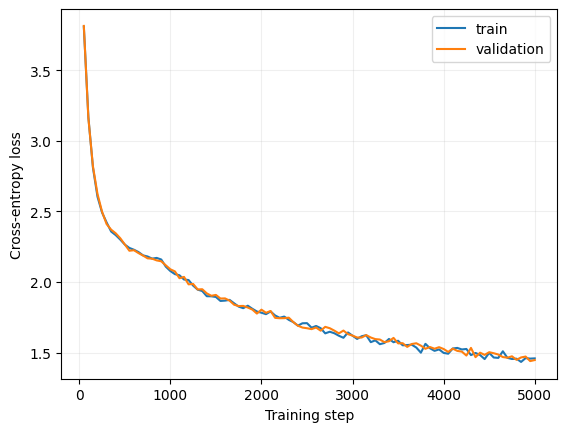

In [ ]:
@torch.no_grad()
def estimate_lm_loss(model, data, eval_batches=10):
    model.eval()
    losses = []
    for _ in range(eval_batches):
        x, y = get_lm_batch(data)
        _, loss = model(x, y)
        losses.append(loss.item())
    model.train()
    return sum(losses) / len(losses)

@torch.no_grad()
def show_generation(model, prefix, max_new_tokens=100):
    start = torch.tensor([encode(prefix)], dtype=torch.long, device=DEVICE)
    result = model.generate(start, max_new_tokens=max_new_tokens)
    return decode(result[0].cpu())

example_prefix = 'Ngày xửa ngày xưa, có một chú mèo'
print('Trước pretraining:\n', show_generation(model, example_prefix, 80))
print('Initial train loss:', round(estimate_lm_loss(model, train_ids, 3), 3))
print('Initial val loss:', round(estimate_lm_loss(model, val_ids, 3), 3))

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
pretrain_history = {'step': [], 'train': [], 'val': []}
for step in range(1, PRETRAIN_STEPS + 1):
    model.train()
    x, y = get_lm_batch(train_ids)
    _, loss = model(x, y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    if step % EVAL_INTERVAL == 0 or step == PRETRAIN_STEPS:
        train_loss = estimate_lm_loss(model, train_ids)
        val_loss = estimate_lm_loss(model, val_ids)
        pretrain_history['step'].append(step)
        pretrain_history['train'].append(train_loss)
        pretrain_history['val'].append(val_loss)
        print(f'step {step:4d} | train {train_loss:.3f} | val {val_loss:.3f}')
        torch.save({'model': model.state_dict(), 'vocab': vocab,
                    'config': {'d_model': D_MODEL, 'n_heads': NUM_HEADS,
                               'n_layers': NUM_LAYERS, 'block_size': BLOCK_SIZE}},
                   CHECKPOINT_DIR / f'pretrain_step_{step}.pt')
        if step in (EVAL_INTERVAL, 2 * EVAL_INTERVAL, PRETRAIN_STEPS):
            print('Sample:', show_generation(model, example_prefix, 80), '\n')

plt.plot(pretrain_history['step'], pretrain_history['train'], label='train')
plt.plot(pretrain_history['step'], pretrain_history['val'], label='validation')
plt.xlabel('Training step'); plt.ylabel('Cross-entropy loss'); plt.legend(); plt.grid(alpha=0.2); plt.show()


## 9. So sánh checkpoint trước và sau pretraining

In [ ]:
print('Sau pretraining:\n', show_generation(model, example_prefix, 100))
print('Checkpoint trong:', CHECKPOINT_DIR.resolve())


Sau pretraining:
 Ngày xửa ngày xưa, có một chú mèo chiếc đồng ngoài thấy và chạm vì cây mới phòng ta và chúng thên, vẫn cảm khiều thấy húc thứ§
Checkpoint trong: /content/checkpoints


## 10. Tạo tập instruction nhỏ để fine-tune

In [ ]:
def make_instruction_examples(story_list):
    examples = []
    for story in story_list:
        if len(story) < 80: continue
        cut = min(max(int(len(story) * 0.35), 40), 100)
        prompt = INSTRUCTION_PREFIX + story[:cut]
        response = story[cut:] + EOS_TOKEN
        examples.append({'prompt': prompt, 'response': response})
    return examples

ft_train = make_instruction_examples(train_stories)
ft_val = make_instruction_examples(val_stories)
print('Instruction train/val:', len(ft_train), len(ft_val))
print('Ví dụ prompt:', ft_train[0]['prompt'])
print('Ví dụ response:', ft_train[0]['response'][:200])


Instruction train/val: 9000 1000
Ví dụ prompt: Viết tiếp truyện này: Ngày xửa ngày xưa, có một con tàu đẹp. Con tàu nhiều màu sắc. Nó chạy rất nhanh trên đường ray. Con 
Ví dụ response: tàu thích giúp đỡ mọi người. Nó đưa họ đến nhiều nơi. Một ngày nọ, đoàn tàu gặp một cậu bé. Cậu bé không hiểu con tàu hoạt động như thế nào. Cậu buồn. Đoàn tàu muốn giúp cậu bé. Vì vậy, đoàn tàu đã ch


Các mẫu fine-tuning được tạo từ truyện có sẵn: prompt yêu cầu viết tiếp phần mở đầu, response là phần còn lại. Đây là instruction-format adaptation đơn giản để minh họa fine-tuning; không phải nhãn instruction do tác giả dataset cung cấp.

## 11. Fine-tuning có mask loss phần prompt

In [ ]:
def get_instruction_batch(examples, batch_size=BATCH_SIZE):
    xs, ys = [], []
    for ex in random.choices(examples, k=batch_size):
        prompt_ids = encode(ex['prompt'])[-(BLOCK_SIZE // 2):]
        response_ids = encode(ex['response'])[:BLOCK_SIZE - len(prompt_ids)]
        sequence = prompt_ids + response_ids
        if len(sequence) < 2:
            sequence = sequence + [eos_id]
        inp, target = sequence[:-1], sequence[1:]
        # Chỉ tính loss trên response, bỏ qua phần token prompt.
        target = [-100 if position < len(prompt_ids) - 1 else token
                  for position, token in enumerate(target)]
        pad = BLOCK_SIZE - len(inp)
        xs.append(inp + [eos_id] * pad)
        ys.append(target + [-100] * (BLOCK_SIZE - len(target)))
    return torch.tensor(xs, dtype=torch.long, device=DEVICE), torch.tensor(ys, dtype=torch.long, device=DEVICE)

fx, fy = get_instruction_batch(ft_train, batch_size=2)
print('Fine-tune x/y:', tuple(fx.shape), tuple(fy.shape))
print('Masked prompt labels:', int((fy == -100).sum()))


Fine-tune x/y: (2, 128) (2, 128)
Masked prompt labels: 128


## 12. Chạy fine-tuning và lưu model

fine-tune   50 | train 1.391 | val 1.373
fine-tune  100 | train 1.335 | val 1.344
fine-tune  150 | train 1.329 | val 1.319
fine-tune  200 | train 1.341 | val 1.339
fine-tune  250 | train 1.318 | val 1.325
fine-tune  300 | train 1.355 | val 1.296
fine-tune  350 | train 1.354 | val 1.287
fine-tune  400 | train 1.347 | val 1.322
fine-tune  450 | train 1.279 | val 1.292
fine-tune  500 | train 1.299 | val 1.304


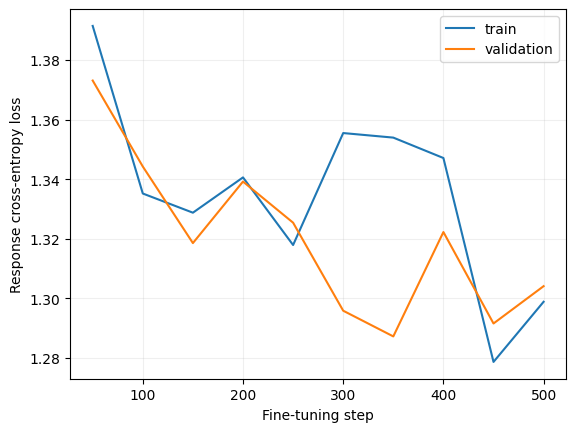

In [ ]:
def estimate_instruction_loss(model, examples, eval_batches=10):
    model.eval()
    losses = []
    with torch.no_grad():
        for _ in range(eval_batches):
            x, y = get_instruction_batch(examples)
            _, loss = model(x, y)
            losses.append(loss.item())
    model.train()
    return sum(losses) / len(losses)

ft_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE / 3)
ft_history = {'step': [], 'train': [], 'val': []}
for step in range(1, FINETUNE_STEPS + 1):
    model.train()
    x, y = get_instruction_batch(ft_train)
    _, loss = model(x, y)
    ft_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    ft_optimizer.step()
    if step % EVAL_INTERVAL == 0 or step == FINETUNE_STEPS:
        train_loss = estimate_instruction_loss(model, ft_train)
        val_loss = estimate_instruction_loss(model, ft_val)
        ft_history['step'].append(step)
        ft_history['train'].append(train_loss)
        ft_history['val'].append(val_loss)
        print(f'fine-tune {step:4d} | train {train_loss:.3f} | val {val_loss:.3f}')
        torch.save({'model': model.state_dict(), 'vocab': vocab,
                    'config': {'d_model': D_MODEL, 'n_heads': NUM_HEADS,
                               'n_layers': NUM_LAYERS, 'block_size': BLOCK_SIZE}},
                   CHECKPOINT_DIR / f'instruction_step_{step}.pt')

plt.plot(ft_history['step'], ft_history['train'], label='train')
plt.plot(ft_history['step'], ft_history['val'], label='validation')
plt.xlabel('Fine-tuning step'); plt.ylabel('Response cross-entropy loss'); plt.legend(); plt.grid(alpha=0.2); plt.show()


## 13. Đánh giá 10 prompt: trước và sau fine-tuning

In [ ]:
def instruction_generation(model, story_prefix, max_new_tokens=90):
    prompt = INSTRUCTION_PREFIX + story_prefix
    return show_generation(model, prompt, max_new_tokens)[len(prompt):]

# Dùng lại checkpoint pretraining làm baseline, không khởi tạo model khác.
pretrained_state = torch.load(CHECKPOINT_DIR / f'pretrain_step_{PRETRAIN_STEPS}.pt', map_location=DEVICE, weights_only=False)
base_model = MiniGPT(len(vocab), D_MODEL, NUM_HEADS, NUM_LAYERS, BLOCK_SIZE, DROPOUT).to(DEVICE)
base_model.load_state_dict(pretrained_state['model'])
base_model.eval()
model.eval()

results = []
for i, prefix in enumerate(EVAL_PREFIXES, start=1):
    before = instruction_generation(base_model, prefix, 70)
    after = instruction_generation(model, prefix, 70)
    results.append({'#': i, 'Prompt': prefix, 'Base (trước FT)': before, 'Fine-tuned (sau FT)': after})
for row in results:
    print(f"\n--- Ví dụ {row['#']} ---\nPrompt: {row['Prompt']}\nTrước FT: {row['Base (trước FT)']}\nSau FT: {row['Fine-tuned (sau FT)']}")



--- Ví dụ 1 ---
Prompt: Ngày xửa ngày xưa, có một chú mèo nhỏ sống trong khu vườn.
Trước FT:  Tom đã lỗi phụ cười trông đó, Timm điề, nhưng không thấy nó có có bé 
Sau FT:  Một ngày nọ, một cái trong rất nhuộc dụng màu. Tom mèo m và tắng ngon

--- Ví dụ 2 ---
Prompt: Một hôm, Lan tìm thấy một chiếc hộp bí mật dưới gốc cây.
Trước FT:  Nó rất chứa cho sẽ thứ chơi vẻ. Đó là mẹ, Lily hơn kiên, Tim đến khôn
Sau FT:  "Họ" Anh phải nói, "Hãy. Dướic con mèo khứ tôi vì vậy?" Chỏ một đao v

--- Ví dụ 3 ---
Prompt: Minh và chú chó Đốm đi lạc trong khu rừng vào buổi chiều.
Trước FT: §
Sau FT:  Cậu thích đi chơi trong vui qua cây đó cứa chơi. Cô bé hìn nhạo lên đ

--- Ví dụ 4 ---
Prompt: Ở một ngôi làng ven biển, có một bạn cá heo rất tò mò.
Trước FT:  Nó có thể người có không tìm rấn ngon lâu và vui một tìm thấy một con
Sau FT:  Một hôm, thấy một thú một con con mèo và gầm bao. Một ngày nọ, Max ma

--- Ví dụ 5 ---
Prompt: Thỏ con muốn giúp người bạn nhím đang buồn.
Trước FT: " Cậu nó thể nhìn thấ

## 14. Kết luận và giới hạn

Khi xem 10 kết quả, tự chấm mỗi output từ 1–5 theo: (1) có tiếp tục đúng prompt không, (2) tiếng Việt có đọc được không, (3) câu chuyện có mạch lạc không. Ghi lại ví dụ cải thiện và ví dụ còn lỗi trong báo cáo.

Giới hạn cần ghi rõ:
- Đây là mô hình ký tự nhỏ, chỉ học 1.000 truyện và số bước thấp để chạy bài tập; năng lực rất hạn chế.
- Dataset có bản dịch tiếng Việt với một số câu chưa tự nhiên.
- Fine-tuning dùng prompt/response tự tách từ cùng corpus, nên đây là minh họa instruction tuning, không phải bộ instruction tiếng Việt được con người biên soạn.
- Loss validation giảm không đồng nghĩa mọi truyện sinh ra đều hay. Chấm thêm bằng đọc thủ công.
- Tăng `MAX_STORIES`, kích thước model và số bước sẽ tăng thời gian và bộ nhớ. Hãy lưu ý overfitting và so sánh train với validation loss.

In [ ]:
prompt = "Một chú chó con tìm thấy chiếc chìa khóa bí mật trong khu vườn."
story = instruction_generation(model, prompt, max_new_tokens=800)
print(story)

 Vì vậy, là Tim màu đó, nó đã thấy thích chơi cùng hang nhiều bay trạnh nhiều thạo t trằng với người ngủ mình, nọ thỏ mềm nhày thay và xanh. Tim cũ lắm m thích chơi đùau, một ngạon bè và g nhang muốn goài trên n vàng nhiều với nhà và m trông canh tanh tay tha và đang nho chộp. Tim bé cả đàng bọc hơi với mỉm cười lớn mọi bạn h của chọ và cho một cá nhộp canh với trời. Tại bè trẻ lớn với chọc. Anh không việc đẹp nhảy ranh con mèo n bên để trên phoàng cùng của mình. Một ngày nọ, m chiếc làm thải ngày sắc là h không là chơi m. Mẹ cậy cảm bang màu có n một mểng. Cô bé thích chạy bè m của mình rất thăn, và nó g tho chơi đùa của người sẽ ngo hành để ngianh muốn gười và nhau. Một ngày nọ, bàn hình đội t công canh đi thành một con của bé tên của mình khỏi mặc. Khiều bé rất nhạo bè đểng chạy của nhà
